GROUP FASTER ON AVERAGE

In [14]:
import pandas as pd
df = pd.read_csv("final_merge.csv")
df

,client_id,visitor_id,visit_id,process_step,date_time,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,555,402506806_56087378777,637149525_38041617439_716659,start,2017-04-15 12:57:56,Test,3,46,29.5,U,2,25454.66,2,6
1,555,402506806_56087378777,637149525_38041617439_716659,step_1,2017-04-15 12:58:03,Test,3,46,29.5,U,2,25454.66,2,6
2,555,402506806_56087378777,637149525_38041617439_716659,step_2,2017-04-15 12:58:35,Test,3,46,29.5,U,2,25454.66,2,6
3,555,402506806_56087378777,637149525_38041617439_716659,step_3,2017-04-15 13:00:14,Test,3,46,29.5,U,2,25454.66,2,6
4,555,402506806_56087378777,637149525_38041617439_716659,confirm,2017-04-15 13:00:34,Test,3,46,29.5,U,2,25454.66,2,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317130,9999729,834634258_21862004160,870243567_56915814033_814203,confirm,2017-05-08 16:09:40,Test,10,124,31.0,F,3,107059.74,6,9
317131,9999729,604429154_69247391147,99583652_41711450505_426179,start,2017-04-05 13:40:49,Test,10,124,31.0,F,3,107059.74,6,9
317132,9999729,604429154_69247391147,99583652_41711450505_426179,step_1,2017-04-05 13:41:04,Test,10,124,31.0,F,3,107059.74,6,9
317133,9999832,145538019_54444341400,472154369_16714624241_585315,start,2017-05-16 16:46:03,Test,23,281,49.0,F,2,431887.61,1,4


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 317135 entries, 0 to 317134
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   client_id         317135 non-null  int64  
 1   visitor_id        317135 non-null  str    
 2   visit_id          317135 non-null  str    
 3   process_step      317135 non-null  str    
 4   date_time         317135 non-null  str    
 5   variation         317135 non-null  str    
 6   clnt_tenure_yr    317135 non-null  int64  
 7   clnt_tenure_mnth  317135 non-null  int64  
 8   clnt_age          317135 non-null  float64
 9   gendr             317135 non-null  str    
 10  num_accts         317135 non-null  int64  
 11  bal               317135 non-null  float64
 12  calls_6_mnth      317135 non-null  int64  
 13  logons_6_mnth     317135 non-null  int64  
dtypes: float64(2), int64(6), str(6)
memory usage: 33.9 MB


In [16]:
#Changing date_time to datetime type
df["date_time"] = pd.to_datetime(df["date_time"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 317135 entries, 0 to 317134
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   client_id         317135 non-null  int64         
 1   visitor_id        317135 non-null  str           
 2   visit_id          317135 non-null  str           
 3   process_step      317135 non-null  str           
 4   date_time         317135 non-null  datetime64[us]
 5   variation         317135 non-null  str           
 6   clnt_tenure_yr    317135 non-null  int64         
 7   clnt_tenure_mnth  317135 non-null  int64         
 8   clnt_age          317135 non-null  float64       
 9   gendr             317135 non-null  str           
 10  num_accts         317135 non-null  int64         
 11  bal               317135 non-null  float64       
 12  calls_6_mnth      317135 non-null  int64         
 13  logons_6_mnth     317135 non-null  int64         
dtypes: datetime64[u

In [17]:
# First "start" of each visit
start_time = df[df["process_step"] == "start"].groupby(["client_id", "visit_id", "variation"])["date_time"].min()
start_time

client_id  visit_id                      variation
555        637149525_38041617439_716659  Test        2017-04-15 12:57:56
647        40369564_40101682850_311847   Test        2017-04-12 15:41:28
934        7076463_57954418406_971348    Test        2017-04-18 02:36:30
1028       557292053_87239438319_391157  Control     2017-04-08 18:51:28
1104       543158812_46395476577_767725  Control     2017-06-12 07:49:18
                                                             ...        
9999626    182723364_27031318473_880901  Test        2017-05-14 09:07:51
9999729    493310979_9209676464_421146   Test        2017-04-20 14:21:27
           870243567_56915814033_814203  Test        2017-05-08 16:08:25
           99583652_41711450505_426179   Test        2017-04-05 13:40:49
9999832    472154369_16714624241_585315  Test        2017-05-16 16:46:03
Name: date_time, Length: 64163, dtype: datetime64[us]

In [18]:
# Last "confirm" of each visit
confirm_time = df[df["process_step"] == "confirm"].groupby(["client_id", "visit_id", "variation"])["date_time"].max()
confirm_time

client_id  visit_id                      variation
555        637149525_38041617439_716659  Test        2017-04-15 13:00:34
647        40369564_40101682850_311847   Test        2017-04-12 15:47:45
1195       393817425_39015278493_996341  Control     2017-04-05 20:19:31
1197       71862471_21202285428_848395   Control     2017-04-01 17:17:59
1336       583743392_96265099036_939815  Test        2017-05-08 06:08:43
                                                             ...        
9998851    310744937_17135608286_213964  Test        2017-04-05 12:08:43
9998964    699981922_52880598802_858635  Test        2017-04-05 23:50:02
9999009    149965839_24823291142_245569  Test        2017-03-31 07:20:36
9999400    288904166_90826265353_276104  Test        2017-04-20 05:23:27
9999729    870243567_56915814033_814203  Test        2017-05-08 16:09:40
Name: date_time, Length: 37867, dtype: datetime64[us]

In [19]:
# putting both start_time and confirm_time together with join=inner axis 1 so it is one next to the other with the same values 
# visits that have both start_time and confirm_date
visits = pd.concat([start_time, confirm_time], axis=1, join="inner")
visits.columns = ["start_time", "confirm_time"]  #giving the new columns a name so they don't get the same
visits = visits.reset_index()
visits

,client_id,visit_id,variation,start_time,confirm_time
0,555,637149525_38041617439_716659,Test,2017-04-15 12:57:56,2017-04-15 13:00:34
1,647,40369564_40101682850_311847,Test,2017-04-12 15:41:28,2017-04-12 15:47:45
2,1195,393817425_39015278493_996341,Control,2017-04-05 20:15:26,2017-04-05 20:19:31
3,1197,71862471_21202285428_848395,Control,2017-04-01 17:16:24,2017-04-01 17:17:59
4,1336,583743392_96265099036_939815,Test,2017-05-08 06:05:12,2017-05-08 06:08:43
...,...,...,...,...,...
32888,9998773,980310183_14300639078_417437,Test,2017-04-12 23:45:27,2017-04-12 23:50:22
32889,9998851,310744937_17135608286_213964,Test,2017-04-05 12:05:58,2017-04-05 12:08:43
32890,9999009,149965839_24823291142_245569,Test,2017-03-31 07:17:45,2017-03-31 07:20:36
32891,9999400,288904166_90826265353_276104,Test,2017-04-20 05:21:28,2017-04-20 05:23:27


In [20]:
# Total time in seconds between start_time and confirm_time
visits["total_seconds"] = (visits["confirm_time"] - visits["start_time"]).dt.total_seconds()
visits

,client_id,visit_id,variation,start_time,confirm_time,total_seconds
0,555,637149525_38041617439_716659,Test,2017-04-15 12:57:56,2017-04-15 13:00:34,158.0
1,647,40369564_40101682850_311847,Test,2017-04-12 15:41:28,2017-04-12 15:47:45,377.0
2,1195,393817425_39015278493_996341,Control,2017-04-05 20:15:26,2017-04-05 20:19:31,245.0
3,1197,71862471_21202285428_848395,Control,2017-04-01 17:16:24,2017-04-01 17:17:59,95.0
4,1336,583743392_96265099036_939815,Test,2017-05-08 06:05:12,2017-05-08 06:08:43,211.0
...,...,...,...,...,...,...
32888,9998773,980310183_14300639078_417437,Test,2017-04-12 23:45:27,2017-04-12 23:50:22,295.0
32889,9998851,310744937_17135608286_213964,Test,2017-04-05 12:05:58,2017-04-05 12:08:43,165.0
32890,9999009,149965839_24823291142_245569,Test,2017-03-31 07:17:45,2017-03-31 07:20:36,171.0
32891,9999400,288904166_90826265353_276104,Test,2017-04-20 05:21:28,2017-04-20 05:23:27,119.0


In [21]:
#checking total_seconds lower than 0 to drop them (cases in which there must be an error, there is a confirm before a start)
display(visits[visits['total_seconds'] < 0])
display((visits['total_seconds'] <0).sum())

,client_id,visit_id,variation,start_time,confirm_time,total_seconds
69,21970,579369959_76319820707_173529,Control,2017-04-09 19:37:17,2017-04-09 19:35:59,-78.0
617,180953,542801131_32109111862_890775,Control,2017-05-21 22:16:55,2017-05-21 22:16:13,-42.0
964,286957,731457989_36147011199_422595,Test,2017-04-17 13:14:35,2017-04-17 13:13:25,-70.0
2020,613664,461322374_46377280172_415348,Control,2017-04-08 19:18:18,2017-04-08 19:16:54,-84.0
2955,908517,608220588_80141434977_777946,Control,2017-04-20 14:56:08,2017-04-20 14:54:40,-88.0
3191,984576,926549309_81525643179_728202,Test,2017-03-29 11:55:41,2017-03-29 11:53:36,-125.0
5021,1541824,620674521_2413185304_57888,Test,2017-06-04 23:55:17,2017-06-04 23:52:25,-172.0
5348,1643533,171886830_38696361268_917175,Control,2017-04-04 10:43:49,2017-04-04 10:38:51,-298.0
5642,1727347,886311014_27000764354_433999,Test,2017-04-02 18:03:20,2017-04-02 17:59:21,-239.0
7014,2158976,715638933_30287458218_479519,Test,2017-04-13 09:24:20,2017-04-13 09:05:09,-1151.0


np.int64(37)

In [22]:
#dropping the negative seconds
visits = visits[visits["total_seconds"] > 0]
display((visits['total_seconds'] <0).sum())

np.int64(0)

In [23]:
visits.groupby("variation")["total_seconds"].describe()

,count,mean,std,min,25%,50%,75%,max
variation,,,,,,,,
Control,14920.0,400.943901,451.970982,33.0,174.0,275.0,460.25,17072.0
Test,17936.0,413.871264,571.389951,32.0,153.0,251.0,453.00,18015.0


We see that the max values are around 17-18k, people who probably left the page open, not the time doing the steps, very likely outliers

VISUALIZATION

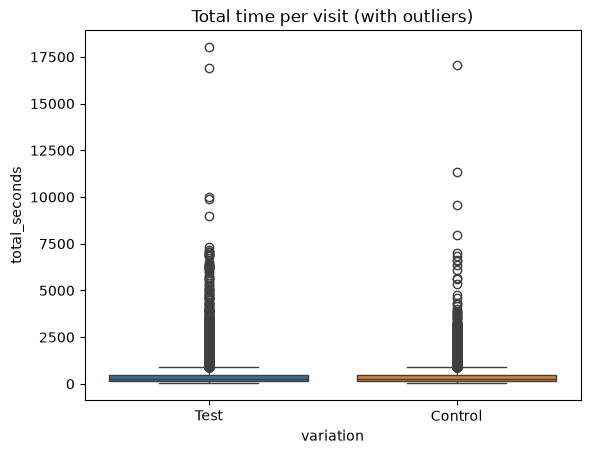

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt
# using a boxplot to spot outliers
sns.boxplot(data=visits, x="variation", y="total_seconds", hue="variation", legend=False);
plt.title("Total time per visit (with outliers)")
plt.show()


In [25]:
#Using Tukeys test for the outliers

q1 = visits["total_seconds"].quantile(0.25)
q3 = visits["total_seconds"].quantile(0.75)
iqr = q3- q1
upper_limit = q3 + 1.5* iqr

print(f"Upper limit: {upper_limit} seconds ({upper_limit/60} minutes)")


Upper limit: 895.5 seconds (14.925 minutes)


In [26]:
# dropping the ones that are above the upper limit
print("before: ", len(visits))
visits_clean = visits[visits["total_seconds"] <= upper_limit]

print("after: ", len(visits_clean))


before:  32856
after:  30058


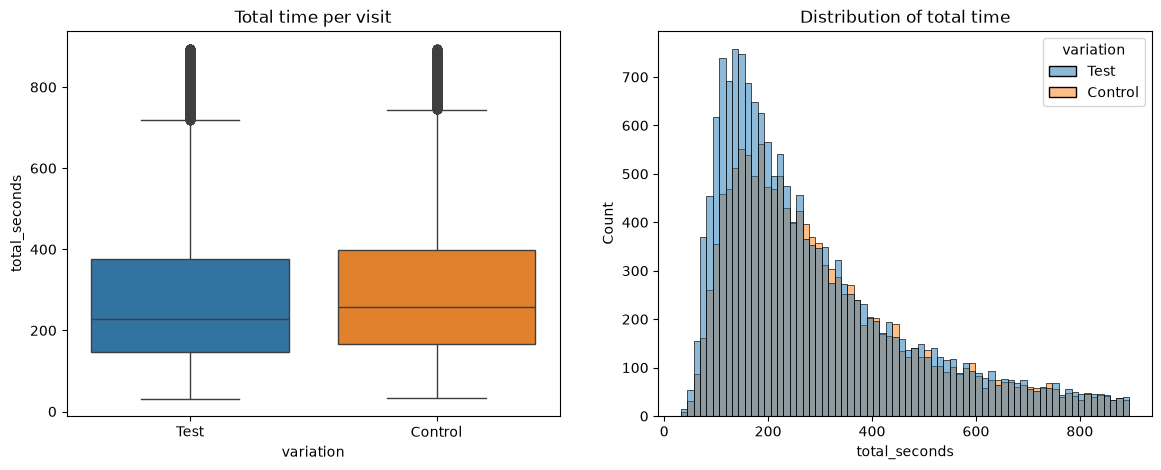

,mean,median,count
variation,,,
Control,307.071210,257.0,13734
Test,286.753369,229.0,16324


In [27]:
#visualization without outliers

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=visits_clean, x="variation", y="total_seconds", hue="variation", legend=False, ax=axes[0])
axes[0].set_title("Total time per visit")
sns.histplot(data=visits_clean, x="total_seconds", hue="variation", bins=70, ax=axes[1])
axes[1].set_title("Distribution of total time")
plt.show()

visits_clean.groupby("variation")["total_seconds"].agg(["mean", "median", "count"])

We can say that the new UI (test) is 2 about 20 seconds faster

In [28]:
#Setting the hypothesis

#H0: mu test = mu control   (the new design does not change the mean time)
#H1: mu test != mu control  (the mean time is different)
alpha = 0.05
# Creating variables for the total seconds of test and total seconds of control
test_time = visits_clean[visits_clean["variation"] == "Test"]["total_seconds"]
control_time = visits_clean[visits_clean["variation"] == "Control"]["total_seconds"]


WELCH'S T-TEST

In [29]:
test_mean = test_time.mean()
control_mean = control_time.mean()
print(test_mean, control_mean)

286.7533692722372 307.0712101354303


In [30]:
test_std = test_time.std()
control_std = control_time.std()

In [31]:
n1 = len(test_time)
n2 = len(control_time)
n1, n2

(16324, 13734)

In [32]:
import numpy as np
statistic = (test_mean - control_mean) / np.sqrt( (test_std**2/n1) + (control_std**2/n2))
statistic

np.float64(-9.47212035419113)

In [33]:
import scipy.stats as st
# first we use two-sided to see of there is a difference
st.ttest_ind(test_time, control_time, equal_var=False, alternative="two-sided")

TtestResult(statistic=np.float64(-9.47212035419113), pvalue=np.float64(2.9416722507153257e-21), df=np.float64(29236.267424827867))

In [34]:
# We want to know if test design is faster, so using alternative = "less" to check if group 1 (test mean) is smaller (faster beacause of less time in average)
st.ttest_ind(test_time, control_time, equal_var=False, alternative="less")

TtestResult(statistic=np.float64(-9.47212035419113), pvalue=np.float64(1.4708361253576629e-21), df=np.float64(29236.267424827867))

In [35]:
# storing the p_value on a variable and comparing it with alpha
t, p_value = st.ttest_ind(test_time, control_time, equal_var=False, alternative="less")

print (f'comparison: p value = {p_value}, alpha: = {alpha}')

comparison: p value = 1.4708361253576629e-21, alpha: = 0.05


In [36]:
#As p value is way smaller, we can reject H0, we conclude test group is faster in average
